In [1]:
%pylab inline
import os
import gc
import fitsio
import csutil
import numpy as np
import catutil
import astropy.io.ascii as ascii
import astropy.table as astTab

Populating the interactive namespace from numpy and matplotlib


In [10]:
datDir='wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/cosmicShear/covariance-wopz/'
csTask=csutil.cs_covariance(datDir)

In [11]:
if False:
    xipC_E0,ximC_E0,xicC_E0=csTask.getCovMat('E0')
    xipC_G,ximC_G,xicC_G=csTask.getCovMat('G')
    xipC_GE0,ximC_GE0,xicC_GE0=csTask.getCovMat('GE0')

In [12]:
# Average
rnom,xip_G,xim_G=csTask.getAve('G')
# Cov
xipC_E1,ximC_E1,xicC_E1=csTask.getCovMat('E1')
xipC_G=xipC_E1/(2*0.814)**4.
ximC_G=ximC_E1/(2*0.814)**4.
xicC_G=xicC_E1/(2*0.814)**4.
# Errorbar
xip_err=np.sqrt(xipC_E1.diagonal()/(2*0.814)**2.)
xim_err=np.sqrt(ximC_E1.diagonal()/(2*0.814)**2.)

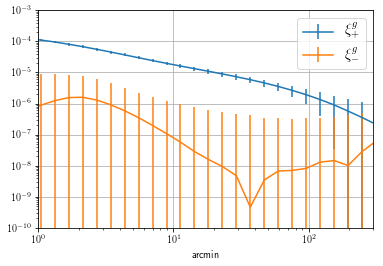

In [5]:
# plot average
plt.close()
plt.errorbar(rnom,xip_G,xip_err,label=r'$\xi_{+}^{g}$')
plt.errorbar(rnom,xim_G,xim_err,label=r'$\xi_{-}^{g}$')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('arcmin')
plt.ylim(1e-10,1e-3)
plt.xlim(1,300.)
plt.grid()
plt.legend(fontsize=15)

In [10]:
def get_CS_SNR(rnom,xip_G,xim_G,xipC_G,ximC_G,xicC_G,min_p_theta=4.,min_m_theta=20):
    idp0 = np.sum(rnom<min_p_theta)
    cov_p= xipC_G[idp0:,idp0:]
    xip  = xip_G[idp0:]
    SNp  = (np.transpose(xip).dot(np.linalg.inv(cov_p).dot(xip)))**0.5
    psize=len(xip)
    #SNpUC = (np.transpose(xip).dot(np.linalg.inv(np.diag(cov_p.diagonal())).dot(xip)))**0.5

    idm0 = np.sum(rnom<min_m_theta)
    cov_m= ximC_G[idm0:,idm0:]
    xim  = xim_G[idm0:]
    SNm   = (np.transpose(xim).dot(np.linalg.inv(cov_m).dot(xim)))**0.5
    msize=len(xim)

    cov_pm= xicC_G[idp0:,idm0:]

    xiAll= np.append(xip,xim)

    cov_full = np.zeros((msize+psize,msize+psize))
    for i in range(msize+psize):
        for j in range(i, msize+psize):
            if i<psize and j<psize:
                cov_full[i][j] = cov_p[i][j]
            elif i<psize and j>=psize:
                cov_full[i][j] = cov_pm[i][j-psize]
            elif i>=psize and j<psize:
                cov_full[i][j] = cov_pm[i-psize][j]
            elif i>=psize and j>=psize:
                cov_full[i][j] = cov_m[i-psize][j-psize]
            cov_full[j][i] = cov_full[i][j]

    SNAll   = (np.transpose(xiAll).dot(np.linalg.inv(cov_full).dot(xiAll)))**0.5
    return SNp,SNm,SNAll

In [11]:
min_p_theta=4.;min_m_theta=20
get_CS_SNR(rnom,xip_G,xim_G,xipC_G,ximC_G,xicC_G,min_p_theta=4.,min_m_theta=20)

(15.255342011257456, 0.21890388247248999, 15.311416786465433)

In [2]:
# try one example and parallize the code for 108*13 sims
e1A=[]
e2A=[]
wA=[]
raA=[]
decA=[]
for fieldname in catutil.field_names:
    catFname=   'wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/catalog_obs_reGaus_no_m/%s_no_m.fits' %(fieldname)
    data   =   fitsio.read(os.path.join(catFname))
    e1PSF,e2PSF= catutil.get_psf_ellip(data)
    ws=data['i_hsmshaperegauss_derived_weight']
    ra=data['i_ra']
    dec=data['i_dec']
    e1A.append(e1PSF)
    e2A.append(e2PSF)
    wA.append(ws)
    raA.append(ra)
    decA.append(dec)
    del data,e1PSF,e2PSF,ws,ra,dec
    gc.collect()

e1A=np.hstack(e1A)
e2A=np.hstack(e2A)
wA=np.hstack(wA)
raA=np.hstack(raA)
decA=np.hstack(decA)

In [4]:
import treecorr
catP   =   treecorr.Catalog(g1=e1A,g2=-e2A,w=wA,ra=raA,dec=decA,ra_units='deg',dec_units='deg') 
# 
corEP  =   treecorr.GGCorrelation(nbins=30,min_sep=0.281838293,max_sep=354.8133892,sep_units='arcmin')
corEP.process(catP)
corEP.write(os.path.join('wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/','ePSF_cov.csv'))

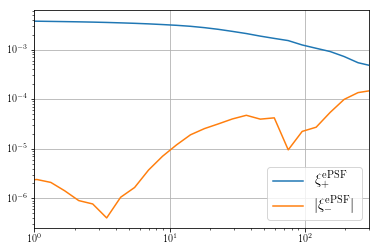

In [20]:
plt.plot(corEP.rnom,corEP.xip,label=r'$\xi_+^{\rm{ePSF}}$')
plt.plot(corEP.rnom,np.abs(corEP.xim),label=r'$|\xi_-^{\rm{ePSF}}|$')
plt.xscale('log')
plt.yscale('log')
plt.xlim(1,300.)
plt.grid()
plt.legend(fontsize=15)
plt.xlabel('arcmin')

Text(0.5, 0, 'arcmin')

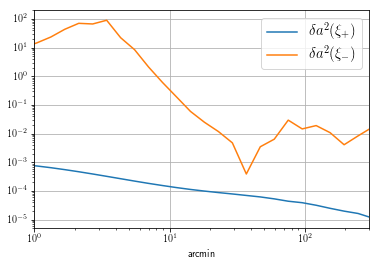

In [25]:
plt.plot(corEP.rnom,xip_G/corEP.xip/40.,label=r'$\delta a^2(\xi_+)$')
plt.plot(corEP.rnom,xim_G/np.abs(corEP.xim/40.),label=r'$\delta a^2(\xi_-)$')
plt.xscale('log')
plt.yscale('log')
plt.xlim(1,300.)
plt.grid()
plt.legend(fontsize=15)
plt.xlabel('arcmin')

In [114]:
a=np.matrix(np.ones(5))
b=np.matrix(np.ones(4))
a.T.dot(b).shape

(5, 4)

In [63]:
idx = (cov_m_ti>min_m_theta) & (cov_m_tj>min_m_theta)
cov_m = cov_m[idx]
msize = np.sum(xi_m.ti.values>min_m_theta)
cov_m = cov_m.reshape((msize, msize))

idx = (cov_p_ti>min_p_theta) & (cov_p_tj>min_p_theta)
cov_p = cov_p[idx]
psize = np.sum(xi_p.ti.values>min_p_theta)
cov_p = cov_p.reshape((psize, psize))

idx = (cov_x_ti>min_p_theta) & (cov_x_tj>min_m_theta)
cov_x = cov_x[idx]
cov_x = cov_x.reshape((psize, msize))

# Now write the full covariance matrix with the pruned vectors
fullcov = np.zeros((msize+psize)*(msize+psize)).reshape((msize+psize,
    msize+psize))

for i in xrange(msize+psize):
    for j in xrange(i, msize+psize):
        if i<psize and j<psize:
            fullcov[i][j] = cov_p[i][j]
        elif i<psize and j>=psize:
            fullcov[i][j] = cov_x[i][j-psize]
        elif i>=psize and j<psize:
            fullcov[i][j] = cov_x[i-psize][j]
        elif i>=psize and j>=psize:
            fullcov[i][j] = cov_m[i-psize][j-psize]
        fullcov[j][i] = fullcov[i][j]

idx_m = xi_m.ti.values>min_m_theta
idx_p = xi_p.ti.values>min_p_theta

xi_p_xi_m_arr = np.append(xi_p.xi.values[idx_p], xi_m.xi.values[idx_m])
theta_arr = np.append(xi_p.ti.values[idx_p], xi_m.ti.values[idx_m])

array([1.81744081e-09, 2.06496703e-10, 1.91620114e-10, 1.99927343e-10,
       1.93981197e-10, 1.65962944e-10, 1.54232325e-10, 1.24772294e-10,
       1.04502677e-10, 9.37692198e-11, 8.61192842e-11, 6.84753558e-11,
       5.98252972e-11, 4.72130410e-11, 3.88066722e-11, 3.28058079e-11,
       2.34489263e-11, 1.98847896e-11, 1.58573962e-11, 1.40490596e-11,
       1.20123432e-11, 1.13675568e-11, 8.00941636e-12, 5.73068507e-12,
       4.17121374e-12, 3.66240750e-12, 2.92389719e-12, 2.55778332e-12,
       2.97237167e-12, 2.85488704e-12])

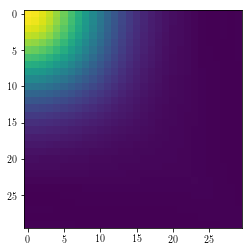

In [150]:
plt.imshow(xip_cov)

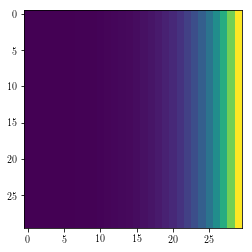

In [149]:
data=ascii.read(fname)
Xgrid,Ygrid=np.meshgrid(data['R_nom'].data,data['R_nom'].data)
plt.imshow(Xgrid)

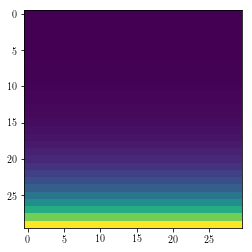

In [143]:
plt.imshow(Ygrid)

In [151]:
xx=np.ravel(Xgrid)
yy=np.ravel(Ygrid)
pp=np.ravel(xip_cov)
mm=np.ravel(xim_cov)

In [102]:
c=b.T.dot(b)

In [97]:
np.cov([1,2],[2,3],rowvar=0)

array([[0.5, 0.5],
       [0.5, 0.5]])

In [134]:
data['R_nom'].data

array([  0.31744,   0.40272,   0.5109 ,   0.64814,   0.82224,   1.0431 ,
         1.3233 ,   1.6788 ,   2.1298 ,   2.7019 ,   3.4277 ,   4.3484 ,
         5.5165 ,   6.9984 ,   8.8784 ,  11.263  ,  14.289  ,  18.127  ,
        22.997  ,  29.174  ,  37.011  ,  46.953  ,  59.566  ,  75.567  ,
        95.866  , 121.62   , 154.29   , 195.73   , 248.31   , 315.02   ])

In [82]:
b=b.reshape(30,1)

In [71]:
np.dot(b,b.T)

1.4599448690924502e-07

In [59]:
a=data['xip']

In [61]:
a.data

array([ 1.6110e-04,  1.5595e-04,  1.4839e-04,  1.3746e-04,  1.2362e-04,
        1.0905e-04,  9.3770e-05,  7.9184e-05,  6.5839e-05,  5.3970e-05,
        4.3705e-05,  3.5078e-05,  2.7934e-05,  2.2153e-05,  1.7754e-05,
        1.4366e-05,  1.1709e-05,  9.6185e-06,  7.9104e-06,  6.4504e-06,
        5.0781e-06,  3.8442e-06,  2.8579e-06,  1.9824e-06,  1.1754e-06,
        6.2023e-07,  4.0602e-07,  1.4700e-07, -2.8016e-07, -1.8681e-07])

In [50]:
data['xip'].data.T.shape

(30,)

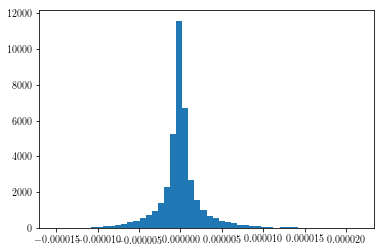

In [35]:
pend='G' #G,E0,E1,GE0
getPlotHist(pend)

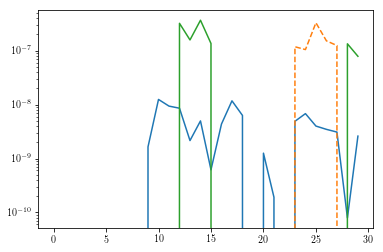

In [93]:
irot=10;isim=45
fname=os.path.join(datDir,'sim-%03d' %isim,'rotmat%d_cor%s.csv' %(irot,pend))
data=ascii.read(fname)
plt.close()
plt.plot(xip_ave)
plt.plot(data['xip'],ls='--')
plt.plot(corGE0.xip,label='gg')
plt.yscale('log')

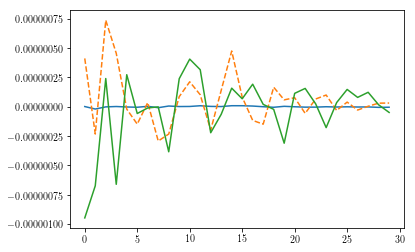

In [94]:
plt.close()
plt.plot(xim_ave)
plt.plot(data['xim'],ls='--')
plt.plot(corGE0.xim,label='gg')

In [ ]:
def plotCS(err_type='total', log_plot=True, theta_p=4.0, theta_m=40.0):
    """
    Routine to make a figure showing the cosmic shear signals and errors.
    """
    # Get the signal plus cosmic variance errors.
    thetap, xip, xip_var, thetam, xim, xim_var = load_CS(0.0, 0.0, unravel=1)

    # Make the plot.
    fig = plt.figure()
    if log_plot:
        plt.plot(thetap, xip, color='red', label=r'$\xi_+$')
        plt.plot(thetam, xim, color='blue', label=r'$\xi_-$')
        if err_type == 'total':
            plt.errorbar(thetap, xip, np.sqrt(xip_var), color='red')
            plt.errorbar(thetam, xim, np.sqrt(xim_var), color='blue')
        elif err_type == 'sn':
            raise RuntimeError("Error type not implemented: %s"%err_type)
            plt.errorbar(thetap, xip, np.sqrt(sn_var), color='red')
            plt.errorbar(thetam, xim, np.sqrt(sn_var), color='blue')
        else:
            raise RuntimeError("Unknown error type: %s"%err_type)

        plt.ylabel(r'$\xi_+$ or $\xi_-$')
        plt.yscale('log')
    else:
        plt.plot(thetap, 1e5*thetap*xip, color='red', label=r'$\theta\xi_+$')
        plt.plot(thetam, 1e5*thetam*xim, color='blue', label=r'$\theta\xi_-$')
        if err_type == 'total':
            plt.errorbar(thetap, 1e5*thetap*xip, 1e5*thetap*np.sqrt(xip_var), color='red')
            plt.errorbar(thetam, 1e5*thetam*xim, 1e5*thetam*np.sqrt(xim_var), color='blue')
        elif err_type == 'sn':
            raise RuntimeError("Error type not implemented: %s"%err_type)
            plt.errorbar(thetap, 1e5*thetap*xip, 1e5*thetap*np.sqrt(sn_var), color='red')
            plt.errorbar(thetam, 1e5*thetam*xim, 1e5*thetam*np.sqrt(sn_var), color='blue')
        else:
            raise RuntimeError("Unknown error type: %s"%err_type)
        plt.ylabel(r'$10^5\theta\xi_+$ or $10^5\theta\xi_-$')

    plt.axvline(theta_p/60.0, linestyle="dashed", color='red')
    plt.axvline(theta_m/60.0, linestyle="dashed", color='blue')
    plt.xlabel(r'$\theta$ [degrees]')
    plt.xscale('log')
    plt.legend()
    return fig

def plot_additive_req_general(outfile=None, theta_p=4.0, theta_m=40.0):
    """
    Routine to make a general plot for requirements on additive errors using
    the first year survey area.
    Based on Sec 3.3.3, Eq. 20
    <cc> = xi_+/SN_CS+
    """

    thetap, xip, xip_var, thetam, xim, xim_var = load_CS(0.0, 0.0, unravel=1)
    SN = getCS_SN(theta_p, theta_m, "p")

    fig = plt.figure()
    plt.plot(thetap, xip/SN, 'b', label=r'$\frac{\xi_+}{%.1f}$' % (SN))
    plt.xlabel(r'$\theta$ [degrees]')
    plt.ylabel(r'Requirement on $\langle cc \rangle$')
    plt.xscale('log')
    plt.yscale('log')

    plt.axvline(theta_p/60.0, linestyle="dashed", color='red')

    dat = np.column_stack([thetap, xip/SN])
    if outfile is not None:
        np.savetxt(outfile, dat, header="Col 1: Theta (degrees) \n Col 2: xip/SN ")

    return fig

def plot_additive_req(fname, theta_p=4.0, theta_m=40.0, stat_factor=0.5, outfile=None):
    """
    Routine to make a plot for requirements on additive errors using the first
    year survey area.
    The user needs to input a filename which contains the shape correlation of stars.
    Based on Sec 3.3.3, Eq. 22
    delta a^2 = stat_factor xi_+/SN_CS+/<estar estar>
    """
    tht, estarxip_all = np.loadtxt(fname, usecols=(0, 1), unpack=1, skiprows=1)

    thetap, xip, xip_var, thetam, xim, xim_var = load_CS(0.0, 0.0, unravel=1)
    SN = getCS_SN(theta_p, theta_m, "p")

    from scipy.interpolate import interp1d
    xip_spl = interp1d(np.log(thetap), np.log(xip), kind="cubic")

    fig = plt.figure()
    plt.plot(tht, stat_factor/SN/estarxip_all*np.exp(xip_spl(np.log(tht))), 'bo', label=r'$\frac{%.1f}{%.1f} \frac{\xi_+}{\langle e_* e_* \rangle}$' % (stat_factor, SN))
    plt.axvline(theta_p/60.0, linestyle="dashed", color='red')
    plt.xlabel(r'$\theta$ [degrees]')
    plt.ylabel(r'Requirement on $\delta (a^2)$')
    plt.xscale('log')
    plt.yscale('log')

    if outfile is not None:
        dat = np.column_stack([tht,stat_factor/SN/estarxip_all*np.exp(xip_spl(np.log(tht)))])
        np.savetxt(outfile, dat, header="Col 1: Theta (degrees) \n Col 2: da2 requirement ")

    return fig

def load_CS(min_p_theta, min_m_theta, unravel=0, retcov=0):

    # Divide all errors and measurements by 4*R**2 where R=0.812, since
    # covariances did not take into account Responsivity in the cosmic shear
    # estimator.  Note this is different from the true Resp in the data, as the
    # mock is constructed by randomly rotating observed ellipticities.
    mockResp = 0.812

    # Read the various files from Masato
    cov_m = pandas.read_csv("HSCS16A_combinedarea_1000rea_full_xi_m.cov",
            usecols=([0, 1, 2]), names=(["ti", "tj", "covar"]), delim_whitespace=1, header=None)
    cov_m_ti = cov_m.ti.values
    cov_m_tj = cov_m.tj.values
    cov_m = cov_m.covar.values/(4.*mockResp**2)**2


    cov_p = pandas.read_csv("HSCS16A_combinedarea_1000rea_full_xi_p.cov",
            usecols=([0, 1, 2]), names=(["ti", "tj", "covar"]), delim_whitespace=1, header=None)
    cov_p_ti = cov_p.ti.values
    cov_p_tj = cov_p.tj.values
    cov_p = cov_p.covar.values/(4.*mockResp**2)**2

    cov_x = pandas.read_csv("HSCS16A_combinedarea_1000rea_full_xi_pm.cross_cov",
            usecols=([0, 1, 2]), names=(["ti", "tj", "covar"]), delim_whitespace=1, header=None)
    cov_x_ti = cov_x.ti.values
    cov_x_tj = cov_x.tj.values
    cov_x = cov_x.covar.values/(4.*mockResp**2)**2

    # Ok now we have to subsample based on theta values
    xi_m = pandas.read_csv("HSCS16A_combinedarea_1000rea_full_xi_m.mean_sqrtvar",
            names=(["ti", "xi", "xi_err"]), header=None, delim_whitespace=1)
    xi_m.xi /= (4.*mockResp**2)
    xi_m.xi_err /= (4.*mockResp**2)

    xi_p = pandas.read_csv("HSCS16A_combinedarea_1000rea_full_xi_p.mean_sqrtvar",
            names=(["ti", "xi", "xi_err"]), header=None, delim_whitespace=1)

    xi_p.xi /= (4.*mockResp**2)
    xi_p.xi_err /= (4.*mockResp**2)

    # Prune theta values
    idx = (cov_m_ti>min_m_theta) & (cov_m_tj>min_m_theta)
    cov_m = cov_m[idx]
    msize = np.sum(xi_m.ti.values>min_m_theta)
    cov_m = cov_m.reshape((msize, msize))

    idx = (cov_p_ti>min_p_theta) & (cov_p_tj>min_p_theta)
    cov_p = cov_p[idx]
    psize = np.sum(xi_p.ti.values>min_p_theta)
    cov_p = cov_p.reshape((psize, psize))

    idx = (cov_x_ti>min_p_theta) & (cov_x_tj>min_m_theta)
    cov_x = cov_x[idx]
    cov_x = cov_x.reshape((psize, msize))

    # Now write the full covariance matrix with the pruned vectors
    fullcov = np.zeros((msize+psize)*(msize+psize)).reshape((msize+psize,
        msize+psize))

    for i in xrange(msize+psize):
        for j in xrange(i, msize+psize):
            if i<psize and j<psize:
                fullcov[i][j] = cov_p[i][j]
            elif i<psize and j>=psize:
                fullcov[i][j] = cov_x[i][j-psize]
            elif i>=psize and j<psize:
                fullcov[i][j] = cov_x[i-psize][j]
            elif i>=psize and j>=psize:
                fullcov[i][j] = cov_m[i-psize][j-psize]
            fullcov[j][i] = fullcov[i][j]

    idx_m = xi_m.ti.values>min_m_theta
    idx_p = xi_p.ti.values>min_p_theta

    xi_p_xi_m_arr = np.append(xi_p.xi.values[idx_p], xi_m.xi.values[idx_m])
    theta_arr = np.append(xi_p.ti.values[idx_p], xi_m.ti.values[idx_m])

    if unravel:
        if not retcov:
            return xi_p.ti.values[idx_p]/60., xi_p.xi.values[idx_p], np.diag(fullcov)[:psize], xi_m.ti.values[idx_m]/60., xi_m.xi.values[idx_m], np.diag(fullcov)[psize:]
        else:
            return xi_p.ti.values[idx_p]/60., xi_p.xi.values[idx_p], fullcov[:psize, :psize], xi_m.ti.values[idx_m]/60., xi_m.xi.values[idx_m], fullcov[psize:, psize:]

    else:
        return theta_arr/60., xi_p_xi_m_arr, fullcov

def getCS_SN(theta_p=4.0, theta_m=40.0, which="a"):
    """
    Routine to read in file with signal and errors for the cosmic shear, assumes the
    first year area
    The covariances include shape noise errors as well
    """
    if which == "a":
        tht, xivec, covar = load_CS(theta_p, theta_m)
        SN = (np.transpose(xivec).dot(inv(covar).dot(xivec)))**0.5
    else:
        thetap, xip, xip_var, thetam, xim, xim_var = load_CS(theta_p, theta_m, unravel=1, retcov=1)
        if which == "m":
            SN = (np.transpose(xim).dot(inv(xim_var).dot(xim)))**0.5
        elif which == "p":
            SN = (np.transpose(xip).dot(inv(xip_var).dot(xip)))**0.5


    print ("Cosmic shear SN: %.2f" % SN)
    return SN